# 02 · Data Cleaning, EDA and Statistical Analysis
**RetailPulse 360 — customer churn on UCI Online Retail II**

This notebook covers **data cleaning & visualisation** and **exploratory data analysis & statistical testing**.

* Cleaning logic lives in `src/retailpulse/cleaning.py` (unit-tested); this notebook loads its output and explains it.
* Customer-level analysis uses one **training-period** cutoff (**2011-03-01**) so that exploring feature/target relationships does not peek at the later validation/test periods.
* Figures are saved to `reports/figures/`.

In [1]:
import sys, os, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats

from src.retailpulse.cleaning import load_clean
from src.retailpulse.features import build_snapshot, build_snapshots, NUMERIC_FEATURES
from src.retailpulse import viz

viz.set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
pd.set_option("display.width", 140)
RNG = np.random.default_rng(42)

tx = load_clean()
log = json.loads(Path("reports/cleaning_log.json").read_text())
audit = json.loads(Path("reports/data_audit.json").read_text())
print(f"Clean transactions: {len(tx):,} rows x {tx.shape[1]} columns")

Clean transactions: 1,030,274 rows x 15 columns


## 1. Data cleaning summary

| Problem | Treatment | Why |
|---|---|---|
| Exact duplicate rows (incl. 1–9 Dec 2010 present in both sheets) | **Removed** | Not real events; would double-count revenue |
| Order + exact cancellation within 1 day (e.g. 80,995 & 74,215 units) | **Removed (both lines)** | Data-entry reversals, never real purchases |
| `Customer ID` stored as float, missing for ~23% | Converted to text ID; **flagged** `has_customer` | Needed for customer tracking; guest rows kept for transaction EDA |
| Cancellations (`C…` invoices) | **Flagged**, excluded from purchases | Feed the customer *return rate* feature |
| Non-product codes (POST, DOT, M, fees, vouchers, …) | **Flagged**, excluded from purchases | Not merchandise; distort basket value |
| Price ≤ 0, adjustments (`A…`) | Excluded from purchases | Free items / accounting entries |
| Missing `Description` | Filled with `UNKNOWN` | Text is not used by the model |
| Large quantities / prices | **Kept**, inspected with IQR rule | Wholesale business: big orders are genuine; handled later by log-transform / tree models |

In [2]:
steps = pd.DataFrame({
    "item": ["Raw rows", "Exact duplicates removed", "Reversed order/cancel lines removed", "Clean rows",
             "  missing Customer ID (flagged)", "  cancellation lines (flagged)", "  non-product lines (flagged)",
             "  price <= 0 (flagged)", "Valid purchase lines with Customer ID"],
    "rows": [log["raw_rows"], log["dropped_exact_duplicates"],
             log["dropped_reversed_purchase_lines"] + log["dropped_reversing_cancellation_lines"],
             log["clean_rows"], log["rows_missing_customer_id"], log["cancellation_rows"],
             log["non_product_rows"], log["nonpositive_price_rows"], log["valid_purchase_rows_with_customer"]],
})
steps["% of raw"] = steps["rows"] / log["raw_rows"] * 100
display(steps.style.format({"rows": "{:,}", "% of raw": "{:.1f}%"}).hide(axis="index"))
print("Dtypes after cleaning:"); print(tx.dtypes.to_string())

item,rows,% of raw
Raw rows,"1,067,371",100.0%
Exact duplicates removed,"34,335",3.2%
Reversed order/cancel lines removed,"2,762",0.3%
Clean rows,"1,030,274",96.5%
missing Customer ID (flagged),"235,151",22.0%
cancellation lines (flagged),"17,723",1.7%
non-product lines (flagged),"5,686",0.5%
price <= 0 (flagged),"6,019",0.6%
Valid purchase lines with Customer ID,"775,265",72.6%


Dtypes after cleaning:
Invoice                      string
StockCode                    string
Description                  string
Quantity                      int64
InvoiceDate          datetime64[us]
Price                       float64
Customer ID                  string
Country                      string
source_sheet                    str
is_cancellation             boolean
is_adjustment               boolean
is_non_product              boolean
has_customer                   bool
Revenue                     float64
is_valid_purchase           boolean


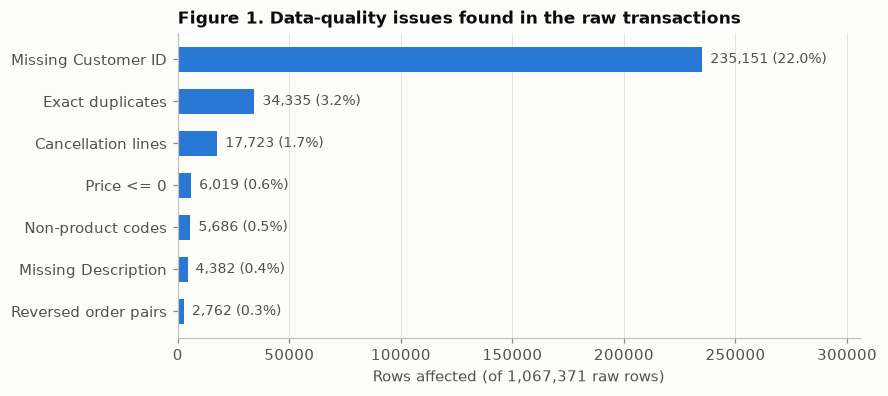

In [3]:
miss = pd.Series(audit["combined"]["missing_by_column"]) / audit["combined"]["rows"] * 100
issues = pd.Series({
    "Missing Customer ID": log["rows_missing_customer_id"],
    "Exact duplicates": log["dropped_exact_duplicates"],
    "Cancellation lines": log["cancellation_rows"],
    "Price <= 0": log["nonpositive_price_rows"],
    "Non-product codes": log["non_product_rows"],
    "Reversed order pairs": log["dropped_reversed_purchase_lines"] * 2,
    "Missing Description": audit["combined"]["missing_by_column"]["Description"],
}).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(issues.index, issues.values, color=viz.BLUE, height=0.6)
for y, v in enumerate(issues.values):
    ax.text(v, y, f"  {v:,} ({v / log['raw_rows'] * 100:.1f}%)", va="center", color=viz.INK_2, fontsize=9)
ax.set_xlabel("Rows affected (of 1,067,371 raw rows)")
ax.set_xlim(0, issues.max() * 1.3); ax.grid(axis="y", visible=False)
ax.set_title("Figure 1. Data-quality issues found in the raw transactions")
viz.save(fig, "fig01_data_quality"); plt.show()

**Interpretation (cleaning).** 3.5% of raw rows were not real business events and were removed: 34,335 exact duplicates, most of them caused by the two sheets overlapping on 1–9 Dec 2010, plus 2,762 lines from order/cancellation pairs reversed within a day. The biggest remaining issue is the **22% of rows without a Customer ID**. These sales are real, so they stay in revenue analysis, but they cannot be linked to a customer and are excluded from churn modelling. Cancellations, non-product codes and zero-price lines are *flagged, not deleted*, so later steps can still use them (for example the return-rate feature). After cleaning, every column has the correct type: IDs as text, dates as datetime, quantities as integers and prices as floats.

## 2. Univariate analysis

In [4]:
valid = tx[tx["is_valid_purchase"]]
orders = (valid.groupby("Invoice")
          .agg(date=("InvoiceDate", "min"), value=("Revenue", "sum"), lines=("StockCode", "size"),
               customer=("Customer ID", "first"), country=("Country", "first")).reset_index())
cust_orders = orders.dropna(subset=["customer"]).groupby("customer").size()

def describe(s):
    return pd.Series({"count": s.size, "mean": s.mean(), "median": s.median(), "std": s.std(),
                      "min": s.min(), "p99": s.quantile(.99), "max": s.max(), "skewness": s.skew()})

uni = pd.DataFrame({"Line quantity": describe(valid["Quantity"]),
                    "Unit price (£)": describe(valid["Price"]),
                    "Line revenue (£)": describe(valid["Revenue"]),
                    "Order value (£)": describe(orders["value"]),
                    "Lines per order": describe(orders["lines"]),
                    "Orders per customer": describe(cust_orders)}).T
uni

,count,mean,median,std,min,p99,max,skewness
Line quantity,"1,002,026.00",10.95,4.00,67.36,1.00,100.00,"19,152.00",99.64
Unit price (£),"1,002,026.00",3.34,2.10,4.74,0.03,16.95,"1,157.15",41.27
Line revenue (£),"1,002,026.00",19.26,10.08,75.62,0.06,179.00,"38,970.00",163.32
Order value (£),"39,400.00",489.70,301.20,"1,123.17",0.19,"4,085.67","52,940.94",18.28
Lines per order,"39,400.00",25.43,15.00,42.66,1.00,198.00,"1,112.00",7.18
Orders per customer,"5,851.00",6.23,3.00,12.68,1.00,45.50,371.00,11.97


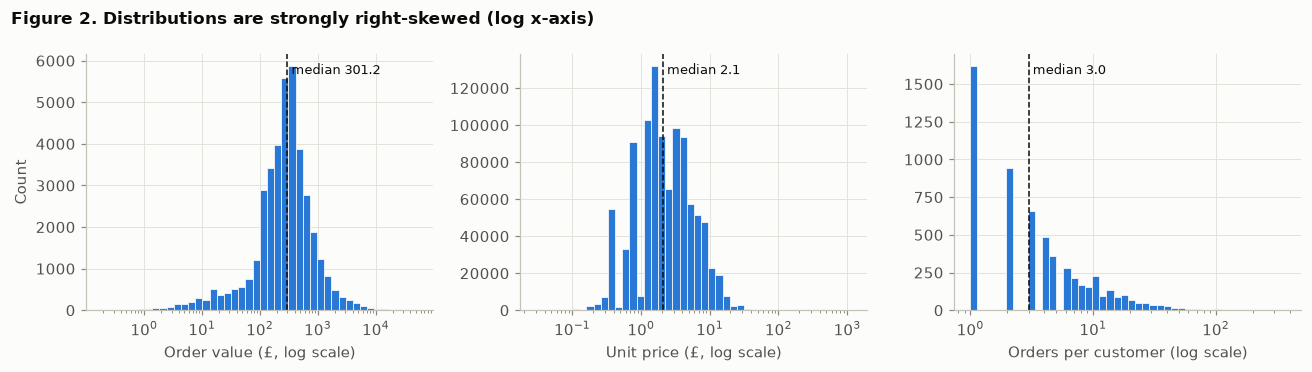

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
panels = [(orders["value"], "Order value (£, log scale)"),
          (valid["Price"], "Unit price (£, log scale)"),
          (cust_orders, "Orders per customer (log scale)")]
for ax, (s, label) in zip(axes, panels):
    bins = np.logspace(np.log10(max(s.min(), 0.01)), np.log10(s.max()), 45)
    ax.hist(s, bins=bins, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=0.5)
    ax.set_xscale("log"); ax.set_xlabel(label); ax.axvline(s.median(), color=viz.INK, lw=1, ls="--")
    ax.text(s.median(), ax.get_ylim()[1] * 0.92, f" median {s.median():,.1f}", color=viz.INK, fontsize=8.5)
axes[0].set_ylabel("Count")
fig.suptitle("Figure 2. Distributions are strongly right-skewed (log x-axis)", x=0.01, ha="left",
             fontweight="bold", fontsize=11)
fig.tight_layout(); viz.save(fig, "fig02_distributions"); plt.show()

In [6]:
oc = log["outliers"]
pd.DataFrame(oc).T[["q1", "q3", "upper_fence", "n_above_fence", "pct_above_fence", "p99", "max"]]

,q1,q3,upper_fence,n_above_fence,pct_above_fence,p99,max
Quantity,1.00,12.00,28.50,"52,687.00",5.26,100.00,"19,152.00"
Price,1.25,4.13,8.45,"74,948.00",7.48,16.95,"1,157.15"
Revenue,4.13,17.70,38.06,"81,729.00",8.16,179.00,"38,970.00"


**Interpretation (univariate).** Every money and volume variable is **heavily right-skewed** (skewness 7–163). For example, the median order is £301 but the mean is £490, and the largest order is £52,941. With the Tukey 1.5×IQR rule, 5–8% of lines count as outliers, but they are **genuine wholesale orders** (e.g. 12,960 units at £0.10), not errors. Removing them would delete the most valuable customers. Decision: **keep them**, and in modelling use log-transforms for linear models and tree-based models, which are insensitive to monotonic scale. Medians, not means, are used to summarise groups.

## 3. Trends over time

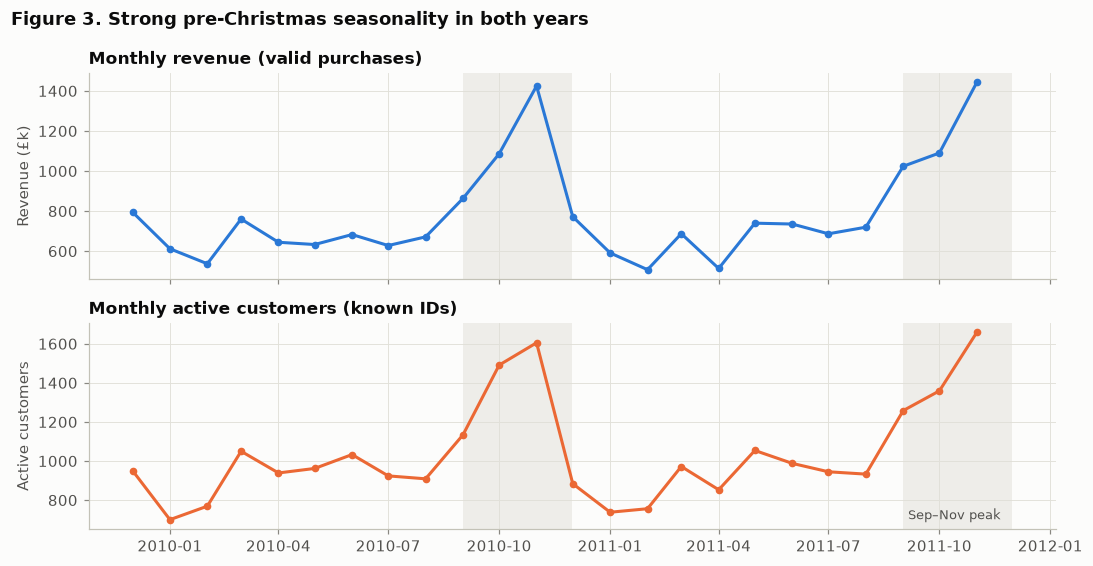

,revenue,customers,orders
month,,,
2010-10,"1,086,456.17",1491,2240
2010-11,"1,424,685.93",1605,2712
2010-12,"772,146.85",884,1545
2011-01,"591,151.48",738,1077
2011-02,"507,591.22",756,1090
2011-03,"687,125.08",972,1436
2011-04,"513,697.36",853,1230
2011-05,"739,766.32",1054,1664
2011-06,"735,463.51",988,1518


In [7]:
monthly = (valid.assign(month=valid["InvoiceDate"].dt.to_period("M"))
           .groupby("month").agg(revenue=("Revenue", "sum"), customers=("Customer ID", "nunique"),
                                 orders=("Invoice", "nunique")))
monthly = monthly.iloc[:-1]   # drop Dec 2011: only 9 days of data
x = monthly.index.to_timestamp()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.2), sharex=True)
a1.plot(x, monthly["revenue"] / 1e3, color=viz.BLUE, marker="o", ms=4)
a1.set_ylabel("Revenue (£k)"); a1.set_title("Monthly revenue (valid purchases)")
a2.plot(x, monthly["customers"], color=viz.ORANGE, marker="o", ms=4)
a2.set_ylabel("Active customers"); a2.set_title("Monthly active customers (known IDs)")
for a in (a1, a2):
    for yr in (2010, 2011):
        a.axvspan(pd.Timestamp(f"{yr}-09-01"), pd.Timestamp(f"{yr}-11-30"), color=viz.GRID, alpha=0.5, lw=0)
a2.text(pd.Timestamp("2011-09-05"), a2.get_ylim()[0] + 50, "Sep–Nov peak", color=viz.INK_2, fontsize=8.5)
fig.suptitle("Figure 3. Strong pre-Christmas seasonality in both years", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); viz.save(fig, "fig03_monthly_trend"); plt.show()
monthly.tail(14)

**Interpretation (trends).** Revenue and active customers both rise sharply from September to November in 2010 and 2011, the pre-Christmas wholesale buying season, peaking at about £1.4M a month in November. January and February are the weakest months. This matters for churn: a customer observed before a quiet period looks more likely to churn than one observed before the peak. The model must therefore be **validated on a later time period**, not on a random split, and seasonality is a named limitation.

## 4. Bivariate analysis — country and shopping time

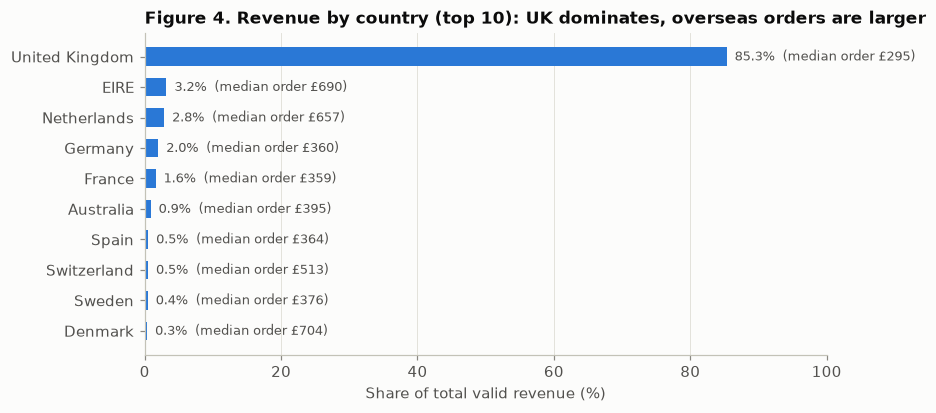

,revenue,customers,orders,median_order,revenue_share_%
Country,,,,,
United Kingdom,"16,463,665.10",5334,36090,295.00,85.33
EIRE,"615,136.28",3,579,690.43,3.19
Netherlands,"549,773.41",22,216,657.08,2.85
Germany,"383,169.10",107,753,360.30,1.99
France,"309,853.49",93,595,359.12,1.61
Australia,"167,498.41",15,86,395.39,0.87
Spain,"97,766.75",38,144,364.37,0.51
Switzerland,"93,634.39",22,83,512.68,0.49
Sweden,"86,081.14",19,98,375.70,0.45


In [8]:
known_orders = orders.dropna(subset=["customer"])
by_country = (valid.groupby("Country").agg(revenue=("Revenue", "sum"), customers=("Customer ID", "nunique"))
              .join(orders.groupby("country").agg(orders=("Invoice", "size"), median_order=("value", "median"))))
by_country["revenue_share_%"] = by_country["revenue"] / by_country["revenue"].sum() * 100
top = by_country.sort_values("revenue", ascending=False).head(10)

fig, ax = plt.subplots(figsize=(8, 3.8))
t = top.iloc[::-1]
ax.barh(t.index, t["revenue_share_%"], color=viz.BLUE, height=0.6)
for y, (share, med) in enumerate(zip(t["revenue_share_%"], t["median_order"])):
    ax.text(share, y, f"  {share:.1f}%  (median order £{med:,.0f})", va="center", fontsize=8.5, color=viz.INK_2)
ax.set_xlabel("Share of total valid revenue (%)"); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.set_title("Figure 4. Revenue by country (top 10): UK dominates, overseas orders are larger")
viz.save(fig, "fig04_country_revenue"); plt.show()
top

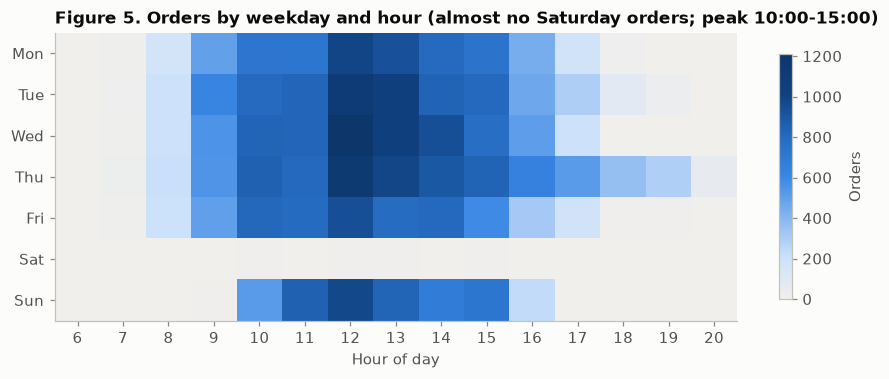

Orders by weekday: {'Mon': 6218, 'Tue': 7125, 'Wed': 7097, 'Thu': 8146, 'Fri': 5968, 'Sat': 30, 'Sun': 4816}


In [9]:
dow = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
heat = (orders.assign(dow=orders["date"].dt.day_of_week, hour=orders["date"].dt.hour)
        .pivot_table(index="dow", columns="hour", values="Invoice", aggfunc="count", fill_value=0)
        .reindex(range(7), fill_value=0))
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(heat.values, cmap=viz.SEQ_BLUE, aspect="auto")
ax.set_yticks(range(7), dow); ax.set_xticks(range(heat.shape[1]), heat.columns); ax.grid(False)
ax.set_xlabel("Hour of day"); fig.colorbar(im, ax=ax, label="Orders", shrink=0.85)
ax.set_title("Figure 5. Orders by weekday and hour (almost no Saturday orders; peak 10:00-15:00)")
viz.save(fig, "fig05_weekday_hour"); plt.show()
print("Orders by weekday:", heat.sum(axis=1).set_axis(dow).to_dict())

**Interpretation (country & time).** The UK generates **85% of revenue** and 91% of customers. A few overseas wholesale accounts are very large (EIRE: 3 customers, 3.2% of revenue), and overseas orders are typically bigger than UK orders (tested in Section 8). Orders arrive almost only on working days. There are only 30 Saturday orders in two years, so the data reflects business-to-business ordering, mostly between 10:00 and 15:00. Weekday and hour describe *when* people buy, not *whether* they come back, so they are not used as churn features.

## 5. Is a 90-day churn window sensible? — gaps between purchases

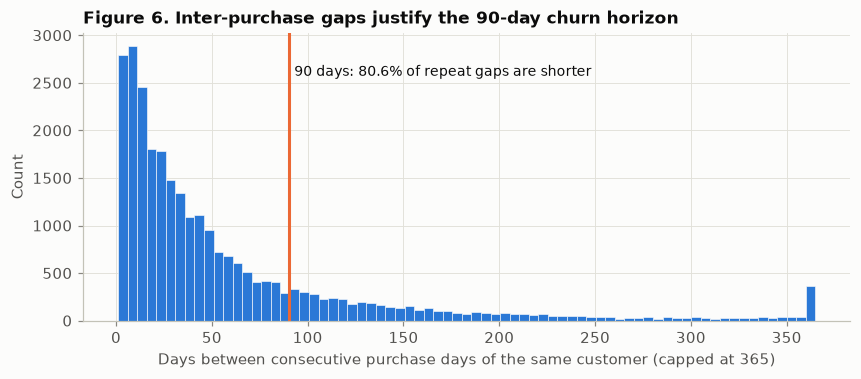

count   26,967.00
mean        59.40
std         78.30
min          1.00
25%         13.00
50%         32.00
75%         71.00
80%         88.00
90%        148.00
max        714.00


In [10]:
days = (known_orders.assign(day=known_orders["date"].dt.normalize())
        .drop_duplicates(["customer", "day"]).sort_values(["customer", "day"]))
gaps = days.groupby("customer")["day"].diff().dt.days.dropna()
share90 = (gaps <= 90).mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist(gaps.clip(upper=365), bins=73, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=0.4)
ax.axvline(90, color=viz.ORANGE, lw=2)
ax.text(93, ax.get_ylim()[1] * 0.85, f"90 days: {share90:.1%} of repeat gaps are shorter",
        color=viz.INK, fontsize=9)
ax.set_xlabel("Days between consecutive purchase days of the same customer (capped at 365)")
ax.set_ylabel("Count"); ax.set_title("Figure 6. Inter-purchase gaps justify the 90-day churn horizon")
viz.save(fig, "fig06_interpurchase_gaps"); plt.show()
print(gaps.describe(percentiles=[.25, .5, .75, .8, .9]).round(1).to_string())

**Interpretation (90-day window).** For returning customers, the median gap between purchase days is **32 days** and **80.6% of gaps are 90 days or less** (80th percentile = 88 days). A customer silent for more than 90 days has therefore broken their usual buying rhythm, which makes `churn_90d` a meaningful label rather than an arbitrary one. A 30-day window would mislabel many regular customers. A 180-day window would leave too few cutoffs in a 2-year dataset.

## 6. Customer-level EDA at a training cutoff (2011-03-01)
Each row = one customer active in the 365 days before 1 Mar 2011. Features use only data **before** the cutoff; `churn_90d` = no purchase in the next 90 days.

In [11]:
snap = build_snapshot(tx, "2011-03-01")
print(f"Eligible customers: {len(snap):,}  |  churn rate: {snap['churn_90d'].mean():.1%}")
display(snap[NUMERIC_FEATURES].describe().T[["mean", "50%", "std", "min", "max"]])
print("Missing values per feature:", snap[NUMERIC_FEATURES].isna().sum()[lambda s: s > 0].to_dict())
group = snap.groupby("churn_90d")[NUMERIC_FEATURES].median().T
group.columns = ["Retained median", "Churned median"]
group["ratio churned/retained"] = group["Churned median"] / group["Retained median"].replace(0, np.nan)
group

Eligible customers: 4,258  |  churn rate: 63.1%


,mean,50%,std,min,max
recency_days,121.55,104.49,91.99,0.29,364.52
frequency,4.22,2.00,7.37,1.00,174.00
monetary,"1,891.85",661.34,"7,509.48",1.55,"254,836.99"
avg_order_value,377.11,284.42,510.69,1.55,"11,880.84"
total_quantity,"1,181.88",369.00,"5,054.80",1.00,"172,845.00"
n_products,61.15,37.00,81.74,1.00,"1,608.00"
active_months,2.92,2.00,2.46,1.00,12.00
tenure_days,284.34,306.59,130.71,0.29,454.68
avg_days_between_orders,64.82,49.11,54.16,0.00,330.08
frequency_recent,0.79,0.00,1.82,0.00,44.00


Missing values per feature: {'avg_days_between_orders': 1496}


,Retained median,Churned median,ratio churned/retained
recency_days,70.61,124.42,1.76
frequency,5.00,2.00,0.40
monetary,"1,468.65",454.66,0.31
avg_order_value,320.20,255.07,0.80
total_quantity,847.00,251.00,0.30
n_products,64.00,27.00,0.42
active_months,4.00,1.00,0.25
tenure_days,360.31,272.35,0.76
avg_days_between_orders,41.18,60.43,1.47
frequency_recent,1.00,0.00,0.00


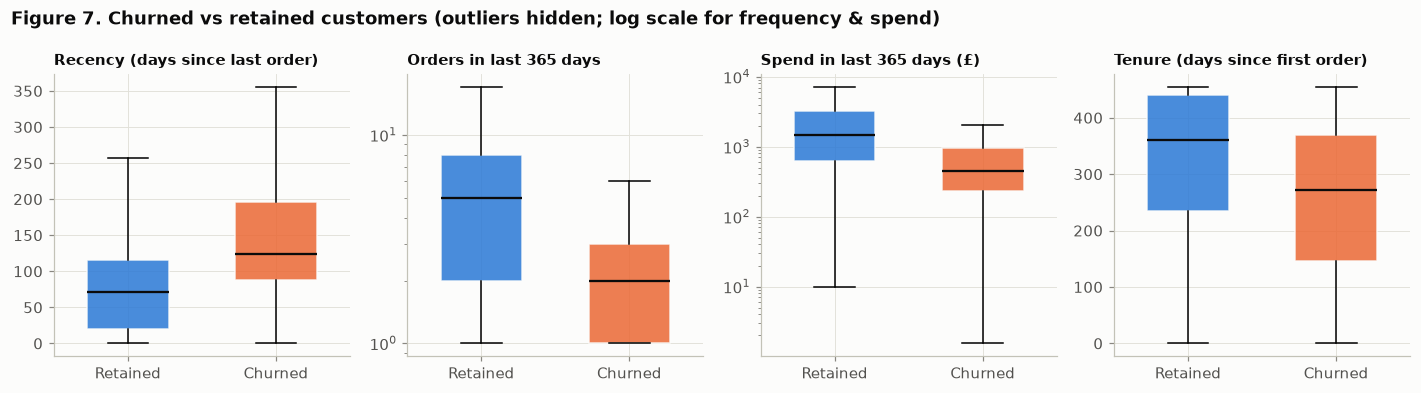

In [12]:
show = [("recency_days", "Recency (days since last order)"), ("frequency", "Orders in last 365 days"),
        ("monetary", "Spend in last 365 days (£)"), ("tenure_days", "Tenure (days since first order)")]
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for ax, (col, label) in zip(axes, show):
    data = [snap.loc[snap["churn_90d"] == k, col] for k in (0, 1)]
    bp = ax.boxplot(data, widths=0.55, showfliers=False, patch_artist=True,
                    medianprops=dict(color=viz.INK, lw=1.5))
    for patch, k in zip(bp["boxes"], (0, 1)):
        patch.set_facecolor(viz.CLASS_COLORS[k]); patch.set_alpha(0.85); patch.set_edgecolor(viz.SURFACE)
    ax.set_xticks([1, 2], ["Retained", "Churned"]); ax.set_title(label, fontsize=9.5)
    if col in ("frequency", "monetary"): ax.set_yscale("log")
fig.suptitle("Figure 7. Churned vs retained customers (outliers hidden; log scale for frequency & spend)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); viz.save(fig, "fig07_churn_vs_retained"); plt.show()

**Interpretation (customer level).** At the 2011-03-01 cutoff, 63.1% of the 4,258 active customers did not buy again within 90 days. Compared with retained customers, churners had **last ordered much longer ago** (median 124 vs 71 days), placed **fewer orders** (2 vs 5), **spent less** (£455 vs £1,469), bought fewer distinct products (27 vs 64) and were newer customers (tenure 272 vs 360 days). This is classic RFM behaviour: engagement, not order size, separates the groups, since average order value differs much less (£255 vs £320). `avg_days_between_orders` is missing for the 1,496 single-order customers because a gap is undefined. It will be **imputed inside the model pipeline** (median, fitted on training data only), not filled here.

## 7. Multivariate analysis

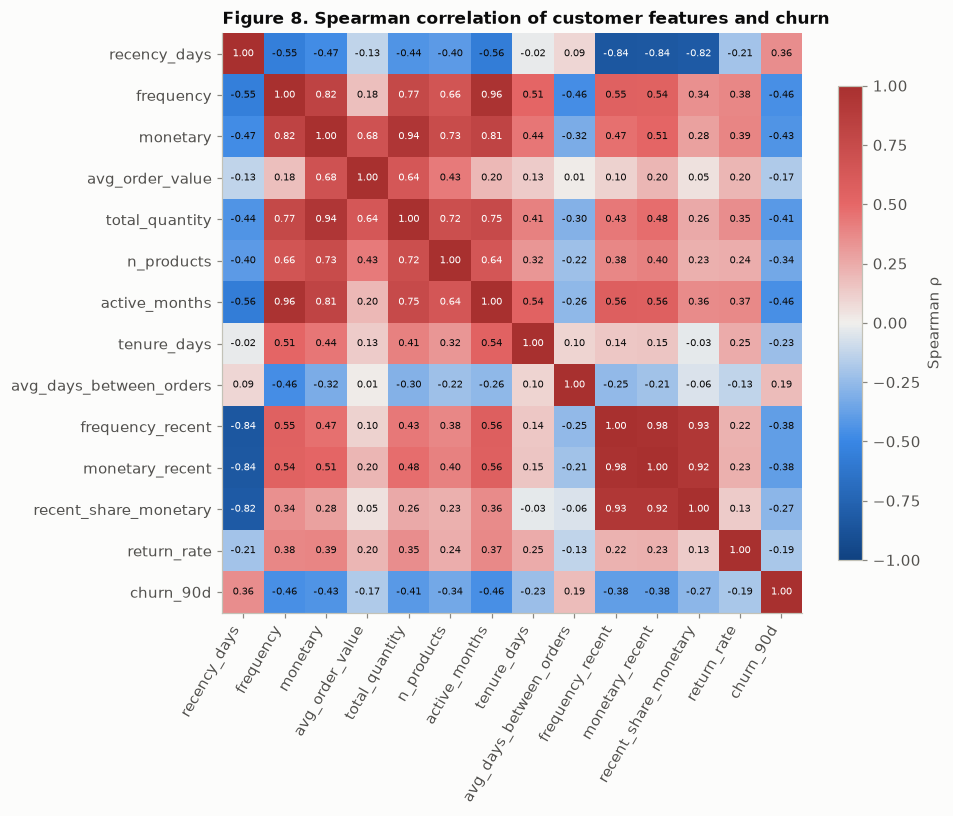

,ρ with churn
active_months,-0.46
frequency,-0.46
monetary,-0.43
total_quantity,-0.41
monetary_recent,-0.38
frequency_recent,-0.38
n_products,-0.34
recent_share_monetary,-0.27
tenure_days,-0.23
return_rate,-0.19


In [13]:
corr = snap[NUMERIC_FEATURES + ["churn_90d"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8.5, 7))
im = ax.imshow(corr.values, cmap=viz.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right"); ax.set_yticks(range(len(corr)), corr.index)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                color="#ffffff" if abs(v) > 0.6 else viz.INK)
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Figure 8. Spearman correlation of customer features and churn")
viz.save(fig, "fig08_correlation"); plt.show()
corr["churn_90d"].drop("churn_90d").sort_values().to_frame("ρ with churn")

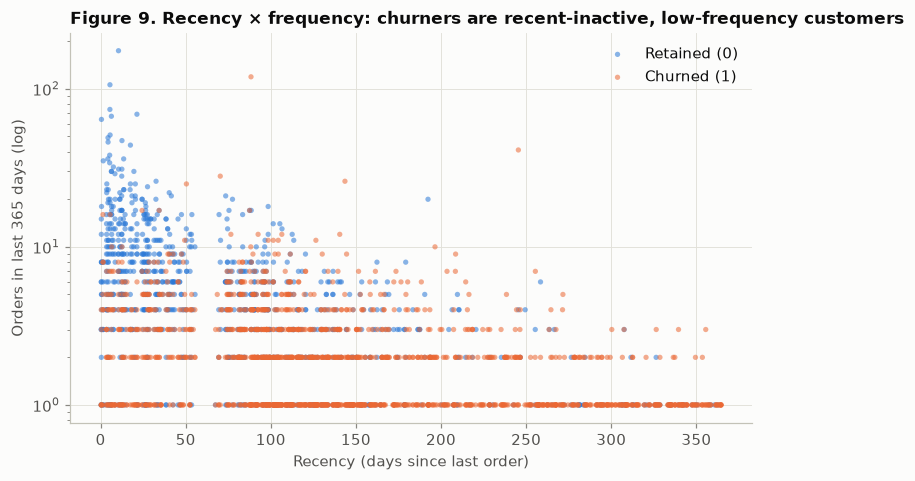

In [14]:
sample = snap.sample(n=min(2500, len(snap)), random_state=42)
fig, ax = plt.subplots(figsize=(8, 4.6))
for k in (0, 1):
    s = sample[sample["churn_90d"] == k]
    ax.scatter(s["recency_days"], s["frequency"], s=12, alpha=0.55, color=viz.CLASS_COLORS[k],
               label=viz.CLASS_NAMES[k], edgecolors="none")
ax.set_yscale("log"); ax.set_xlabel("Recency (days since last order)"); ax.set_ylabel("Orders in last 365 days (log)")
ax.legend(loc="upper right"); ax.set_title("Figure 9. Recency × frequency: churners are recent-inactive, low-frequency customers")
viz.save(fig, "fig09_recency_frequency"); plt.show()

**Interpretation (multivariate).** The features most strongly related to churn are **active months, frequency and monetary value** (Spearman ρ ≈ −0.43 to −0.46) and **recency** (ρ = +0.36). Several features are strongly correlated with each other: frequency, active months, monetary value, quantity and product count. This **multicollinearity** makes individual Logistic Regression coefficients unstable, so regularisation (L2) will be used, and feature importance will be read from permutation importance rather than raw coefficients. The scatter plot shows that churners cluster at **high recency and low frequency**, but the classes overlap, so a single rule is not enough. That supports using a multivariate model.

## 8. Statistical tests and confidence intervals
Significance level α = 0.05. Customer features are heavily skewed (Section 2), so **non-parametric** tests are used instead of t-tests.

**Test 1 — Mann–Whitney U.** H0: churned and retained customers have the same distribution of the feature. Effect size = rank-biserial correlation *r* (|r| ≈ 0.1 small, 0.3 medium, 0.5 large).

In [15]:
rows = []
for col in ["recency_days", "frequency", "monetary", "n_products", "tenure_days", "return_rate"]:
    a = snap.loc[snap["churn_90d"] == 1, col]; b = snap.loc[snap["churn_90d"] == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    r = 2 * u / (len(a) * len(b)) - 1      # rank-biserial: P(churned > retained) - P(churned < retained)
    rows.append({"feature": col, "median churned": a.median(), "median retained": b.median(),
                 "U": u, "p-value": p, "rank-biserial r": r, "reject H0": p < 0.05})
mw = pd.DataFrame(rows)
mw.style.format({"median churned": "{:,.2f}", "median retained": "{:,.2f}", "U": "{:,.0f}",
                 "p-value": "{:.2e}", "rank-biserial r": "{:+.3f}"}).hide(axis="index")

feature,median churned,median retained,U,p-value,rank-biserial r,reject H0
recency_days,124.42,70.61,"3,013,202",2.91e-120,+0.428,True
frequency,2.00,5.00,"986,975",1.99e-195,-0.532,True
monetary,454.66,"1,468.65","1,023,604",1.54e-173,-0.515,True
n_products,27.00,64.00,"1,242,591",2.11e-111,-0.411,True
tenure_days,272.35,360.31,"1,537,840",1.50e-49,-0.271,True
return_rate,0.00,0.00,"1,694,552",1.11e-35,-0.197,True


**Test 2 — Chi-square test of independence.** H0: churn is independent of whether the customer is UK-based. Effect size = Cramér's V.

In [16]:
ct = pd.crosstab(np.where(snap["country"] == "United Kingdom", "UK", "International"), snap["churn_90d"])
ct.columns = ["Retained", "Churned"]
chi2, p, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))
display(ct.assign(**{"churn rate": ct["Churned"] / ct.sum(axis=1)}))
print(f"chi2 = {chi2:.2f}, dof = {dof}, p = {p:.4f}, Cramér's V = {cramers_v:.3f}")
print("Expected counts all >= 5:", bool((expected >= 5).all()))

,Retained,Churned,churn rate
row_0,,,
International,136,216,0.61
UK,1435,2471,0.63


chi2 = 0.42, dof = 1, p = 0.5162, Cramér's V = 0.010
Expected counts all >= 5: True


**Test 3 — Order value, UK vs international.** Mann–Whitney U plus a **bootstrap 95% confidence interval** for the difference in median order value (2,000 resamples).

In [17]:
ov = known_orders.assign(region=np.where(known_orders["country"] == "United Kingdom", "UK", "International"))
uk, intl = ov.loc[ov.region == "UK", "value"].to_numpy(), ov.loc[ov.region == "International", "value"].to_numpy()
u, p = stats.mannwhitneyu(intl, uk, alternative="two-sided")
boots = np.array([np.median(RNG.choice(intl, intl.size)) - np.median(RNG.choice(uk, uk.size)) for _ in range(2000)])
lo, hi = np.percentile(boots, [2.5, 97.5])
print(f"Median order value  UK: £{np.median(uk):,.2f} (n={uk.size:,})   International: £{np.median(intl):,.2f} (n={intl.size:,})")
print(f"Mann-Whitney U p = {p:.2e}")
print(f"Difference in medians (Intl - UK): £{np.median(intl) - np.median(uk):,.2f}, 95% bootstrap CI [£{lo:,.2f}, £{hi:,.2f}]")

Median order value  UK: £299.38 (n=33,267)   International: £421.60 (n=3,211)
Mann-Whitney U p = 1.31e-143
Difference in medians (Intl - UK): £122.22, 95% bootstrap CI [£104.57, £142.39]


**Confidence intervals for the churn rate across cutoffs** (Wilson 95% interval). Only the label is examined here — this informs the time-based split and seasonality, not feature selection.

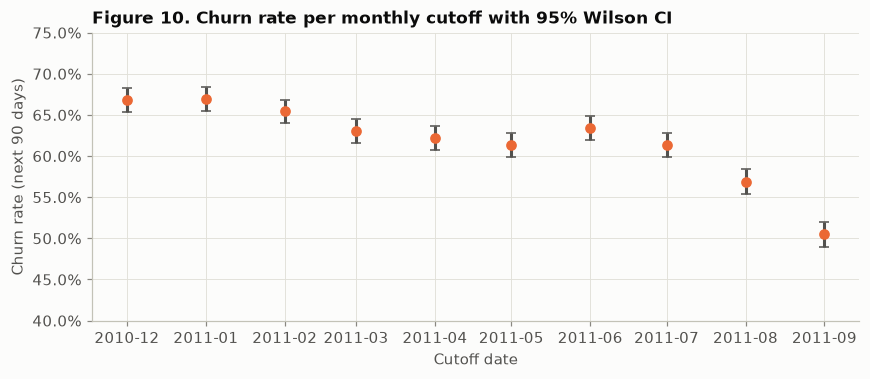

,churned,eligible,churn_rate,ci_low,ci_high
cutoff,,,,,
2010-12-01,2831,4236,0.67,0.65,0.68
2011-01-01,2814,4202,0.67,0.66,0.68
2011-02-01,2760,4218,0.65,0.64,0.67
2011-03-01,2687,4258,0.63,0.62,0.65
2011-04-01,2686,4316,0.62,0.61,0.64
2011-05-01,2647,4317,0.61,0.60,0.63
2011-06-01,2741,4324,0.63,0.62,0.65
2011-07-01,2647,4313,0.61,0.60,0.63
2011-08-01,2461,4325,0.57,0.55,0.58


In [18]:
def wilson(k, n, z=1.96):
    p = k / n; d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return c - h, c + h

cutoffs = pd.date_range("2010-12-01", "2011-09-01", freq="MS")
labels = build_snapshots(tx, cutoffs)[["cutoff", "Customer ID", "churn_90d"]]
rate = labels.groupby("cutoff")["churn_90d"].agg(["sum", "size", "mean"])
rate[["ci_low", "ci_high"]] = [wilson(k, n) for k, n in zip(rate["sum"], rate["size"])]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.errorbar(rate.index, rate["mean"], yerr=[rate["mean"] - rate["ci_low"], rate["ci_high"] - rate["mean"]],
            fmt="o", color=viz.ORANGE, ecolor=viz.INK_2, capsize=3, ms=6)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(0.4, 0.75)
ax.set_ylabel("Churn rate (next 90 days)"); ax.set_xlabel("Cutoff date")
ax.set_title("Figure 10. Churn rate per monthly cutoff with 95% Wilson CI")
viz.save(fig, "fig10_churn_rate_ci"); plt.show()
rate.rename(columns={"sum": "churned", "size": "eligible", "mean": "churn_rate"})

**Interpretation (statistical tests).**

1. **Mann–Whitney U (churned vs retained):** all six features differ significantly (p < 10⁻³⁰). This is not just a large-sample effect: the effect sizes are **large** for frequency (r = −0.53) and monetary value (r = −0.52), and **medium** for recency (r = +0.43) and product variety (r = −0.41). Return rate is significant but small (r = −0.20). Customers who return items are slightly *less* likely to churn, probably because returns happen among active, high-volume buyers.
2. **Chi-square (UK vs international × churn):** χ² = 0.42, p = 0.52, Cramér's V = 0.01. We **fail to reject H0**: being UK-based is *not* associated with churn. Country is therefore expected to add little to the model. It is kept as a low-cost categorical feature, and this result is reported as a finding in its own right.
3. **Order value, UK vs international:** international orders are larger (median £422 vs £299, p ≈ 10⁻¹⁴³). The 95% bootstrap CI for the difference is **£105 to £142**, which excludes 0. Country affects *how much* customers spend per order, not *whether* they come back.
4. **Churn-rate confidence intervals:** the 95% Wilson intervals are narrow (about ±1.5 points). The drop from about 66% (Dec–Feb cutoffs) to **50.5% (Sep 2011)** is therefore a real seasonal shift, not noise. A test set taken from the latest cutoff will have a different base rate from training, so metrics that do not depend on the base rate (ROC-AUC) are reported alongside PR-AUC.

## 9. Key findings and implications for modelling

| # | Finding | Consequence for modelling |
|---|---|---|
| 1 | 22% of rows lack a Customer ID; 3.5% were duplicates or reversals | Model only customers with an ID; transparent cleaning log |
| 2 | Money and volume variables are extremely right-skewed; IQR outliers are genuine wholesale orders | Keep outliers; `log1p` + scaling for linear/KNN models; tree models need no scaling |
| 3 | 80.6% of repeat gaps ≤ 90 days | 90-day churn horizon is justified |
| 4 | Churners: higher recency, lower frequency, spend and variety (large effect sizes) | RFM-style features should give a strong signal; aim for ROC-AUC ≥ 0.75 |
| 5 | Frequency, monetary value, active months and product count are highly inter-correlated | L2-regularised Logistic Regression; permutation importance for interpretation |
| 6 | Country is not associated with churn (χ² p = 0.52) | Low expected importance; keep as one grouped categorical feature |
| 7 | Churn is the majority class (≈ 61–67%) and falls to 50.5% for the Sep-2011 cutoff (seasonality) | **Time-based split** (train on earlier cutoffs, test on the latest); report ROC-AUC, PR-AUC, macro-F1 against a majority-class baseline; tune the decision threshold on validation data |
| 8 | `avg_days_between_orders` undefined for single-order customers | Median imputation **inside** the sklearn pipeline to avoid leakage |